# SafeFlow — PeMS Exploratory Data Analysis

This notebook performs the first exploratory analysis of the direct Caltrans PeMS
5-minute station dataset.

## Main questions
1. Is the downloaded dataset complete and internally consistent?
2. Which stations/directions have usable coverage?
3. What do the distributions of speed, flow, and occupancy look like?
4. What daily and weekly traffic patterns are present?
5. How persistent are traffic states over a 30-minute horizon?
6. Which stations/directions appear most useful for the initial forecasting model?

This notebook is intentionally limited to EDA. Modeling should go in a later notebook.

## 1. Setup and configuration

Edit only the configuration block below if the filename or corridor changes.
The code assumes the notebook lives in `notebooks/` inside the SafeFlow repository.

In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW_DIR = ROOT / "data" / "raw" / "pems"

# ---- EDIT THESE IF NEEDED ----
DATA_FILE = RAW_DIR / "d07_2019_10_station_5min.csv"
FREEWAY = 405
FORECAST_HORIZON_MIN = 30
SAMPLING_INTERVAL_MIN = 5
# ------------------------------

FORECAST_STEPS = FORECAST_HORIZON_MIN // SAMPLING_INTERVAL_MIN

print("Repository root:", ROOT)
print("Data file:", DATA_FILE)
print("Exists:", DATA_FILE.exists())
print("30-min forecast steps:", FORECAST_STEPS)

Repository root: c:\Erdos\Project\safeflow
Data file: c:\Erdos\Project\safeflow\data\raw\pems\d07_2019_10_station_5min.csv
Exists: True
30-min forecast steps: 6


## 2. Load the data

The team downloader produces station-level 5-minute observations. No rows are removed here.

In [11]:
df = pd.read_csv(
    DATA_FILE,
    parse_dates=["Timestamp"],
    low_memory=False,
)

print("Shape:", df.shape)
display(df.head())

Shape: (5740061, 12)


,Timestamp,Station,District,Freeway #,Direction of Travel,Lane Type,Station Length,Samples,% Observed,Total Flow,Avg Occupancy,Avg Speed
0,2019-10-01,716617,7,405,N,OR,NaN,5,0,NaN,NaN,NaN
1,2019-10-01,716619,7,405,S,OR,NaN,5,0,NaN,NaN,NaN
2,2019-10-01,716620,7,405,N,OR,NaN,5,100,22.0,0.0412,NaN
3,2019-10-01,716621,7,405,S,OR,NaN,5,100,2.0,0.0022,NaN
4,2019-10-01,716622,7,405,N,OR,NaN,5,100,0.0,0.0000,NaN


## 3. Basic schema and integrity checks

In [12]:
print("Columns:")
print(df.columns.tolist())

print("\nDate range:")
print(df["Timestamp"].min(), "to", df["Timestamp"].max())

print("\nUnique stations:", df["Station"].nunique())
print("Unique freeways:", sorted(df["Freeway #"].dropna().unique().tolist()))
print("Directions:", sorted(df["Direction of Travel"].dropna().astype(str).unique().tolist()))

print("\nExact duplicate rows:", df.duplicated().sum())

Columns:
['Timestamp', 'Station', 'District', 'Freeway #', 'Direction of Travel', 'Lane Type', 'Station Length', 'Samples', '% Observed', 'Total Flow', 'Avg Occupancy', 'Avg Speed']

Date range:
2019-10-01 00:00:00 to 2019-10-31 23:55:00

Unique stations: 643
Unique freeways: [405]
Directions: ['N', 'S']

Exact duplicate rows: 0


### Check expected 5-minute cadence

Check cadence within one station, not across the full table.

In [13]:
sample_station = df["Station"].dropna().iloc[0]

sample_times = (
    df.loc[df["Station"] == sample_station, "Timestamp"]
      .sort_values()
)

display(sample_times.diff().value_counts().head(10))

Timestamp
0 days 00:05:00    8925
0 days 00:10:00       1
Name: count, dtype: int64

## 4. Restrict to the intended freeway

In [14]:
df_corridor = df.loc[df["Freeway #"] == FREEWAY].copy()

print("Rows on selected freeway:", len(df_corridor))
print("Stations:", df_corridor["Station"].nunique())
print("Directions:", sorted(df_corridor["Direction of Travel"].dropna().astype(str).unique().tolist()))

Rows on selected freeway: 5740061
Stations: 643
Directions: ['N', 'S']


## 5. Data quality and missingness

Distinguish actual null values from PeMS `% Observed`, which records observation quality.
Do not drop low-quality data yet.

In [15]:
key_cols = [
    "Timestamp",
    "Station",
    "Direction of Travel",
    "% Observed",
    "Total Flow",
    "Avg Occupancy",
    "Avg Speed",
]

missing_summary = (
    df_corridor[key_cols]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .to_frame("missing_percent")
)

display(missing_summary)

,missing_percent
Avg Speed,35.458787
Total Flow,14.275894
Avg Occupancy,14.275894
Direction of Travel,0.000000
Station,0.000000
Timestamp,0.000000
% Observed,0.000000


count    5.740061e+06
mean     6.447236e+01
std      4.619105e+01
min      0.000000e+00
25%      0.000000e+00
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
Name: % Observed, dtype: float64


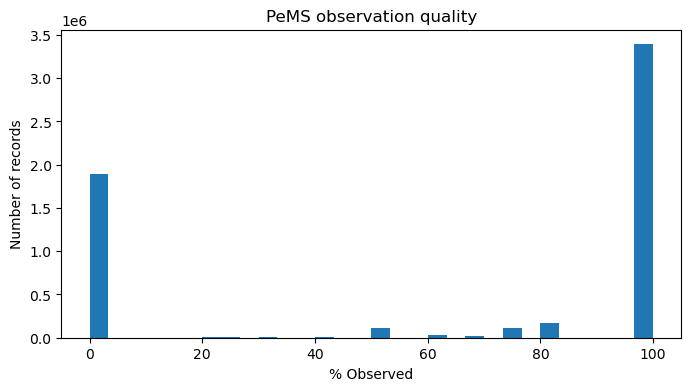

In [16]:
obs = pd.to_numeric(df_corridor["% Observed"], errors="coerce")

print(obs.describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(obs.dropna().to_numpy(), bins=30)
ax.set_xlabel("% Observed")
ax.set_ylabel("Number of records")
ax.set_title("PeMS observation quality")
plt.show()

### Coverage by station

In [17]:
station_summary = (
    df_corridor.groupby(["Station", "Direction of Travel"])
    .agg(
        n_rows=("Timestamp", "size"),
        start=("Timestamp", "min"),
        end=("Timestamp", "max"),
        speed_missing=("Avg Speed", lambda s: s.isna().mean()),
        flow_missing=("Total Flow", lambda s: s.isna().mean()),
        occupancy_missing=("Avg Occupancy", lambda s: s.isna().mean()),
        mean_observed=("% Observed", "mean"),
    )
    .reset_index()
)

display(station_summary.sort_values("speed_missing", ascending=False).head(20))

,Station,Direction of Travel,n_rows,start,end,speed_missing,flow_missing,occupancy_missing,mean_observed
0,716617,N,8927,2019-10-01,2019-10-31 23:55:00,1.0,1.000000,1.000000,0.000000
1,716619,S,8927,2019-10-01,2019-10-31 23:55:00,1.0,1.000000,1.000000,0.000000
2,716620,N,8927,2019-10-01,2019-10-31 23:55:00,1.0,0.036518,0.036518,96.348157
3,716621,S,8927,2019-10-01,2019-10-31 23:55:00,1.0,0.036518,0.036518,96.348157
4,716622,N,8927,2019-10-01,2019-10-31 23:55:00,1.0,0.036518,0.036518,96.348157
5,716623,S,8927,2019-10-01,2019-10-31 23:55:00,1.0,0.036518,0.036518,96.348157
6,716624,N,8927,2019-10-01,2019-10-31 23:55:00,1.0,0.036630,0.036630,96.336955
7,716625,S,8927,2019-10-01,2019-10-31 23:55:00,1.0,0.036518,0.036518,96.348157
288,718301,S,8927,2019-10-01,2019-10-31 23:55:00,1.0,0.043352,0.043352,95.664837
9,716628,S,8927,2019-10-01,2019-10-31 23:55:00,1.0,0.036518,0.036518,96.348157


## 6. Traffic-variable distributions

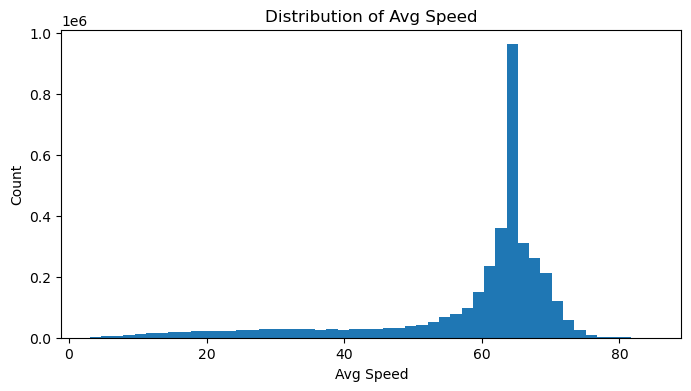

Avg Speed


count    3.704705e+06
mean     5.836367e+01
std      1.406093e+01
min      3.000000e+00
25%      5.760000e+01
50%      6.410000e+01
75%      6.550000e+01
max      8.490000e+01
Name: Avg Speed, dtype: float64

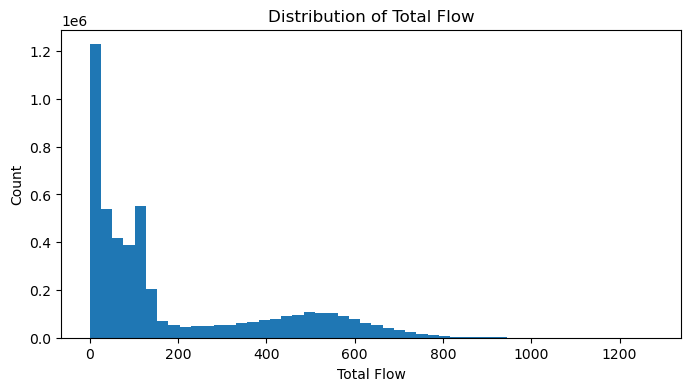

Total Flow


count    4.920616e+06
mean     1.858590e+02
std      2.129650e+02
min      0.000000e+00
25%      2.600000e+01
50%      9.500000e+01
75%      3.230000e+02
max      1.276000e+03
Name: Total Flow, dtype: float64

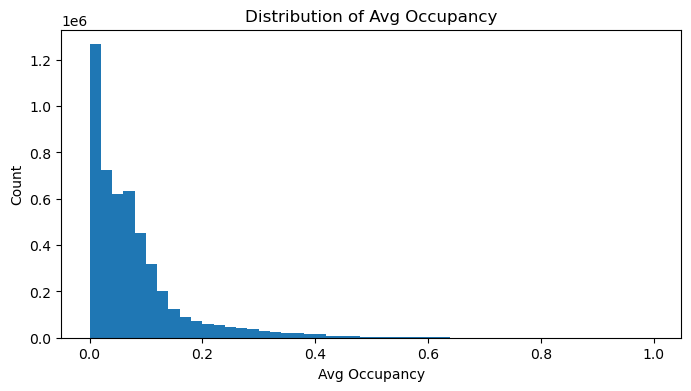

Avg Occupancy


count    4.920616e+06
mean     7.825625e-02
std      8.843640e-02
min      0.000000e+00
25%      1.920000e-02
50%      5.540000e-02
75%      9.970000e-02
max      9.989000e-01
Name: Avg Occupancy, dtype: float64

In [18]:
plot_vars = ["Avg Speed", "Total Flow", "Avg Occupancy"]

for col in plot_vars:
    values = pd.to_numeric(df_corridor[col], errors="coerce").dropna()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(values.to_numpy(), bins=50)
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.set_title(f"Distribution of {col}")
    plt.show()

    print(col)
    display(values.describe())

## 7. Corridor temporal patterns

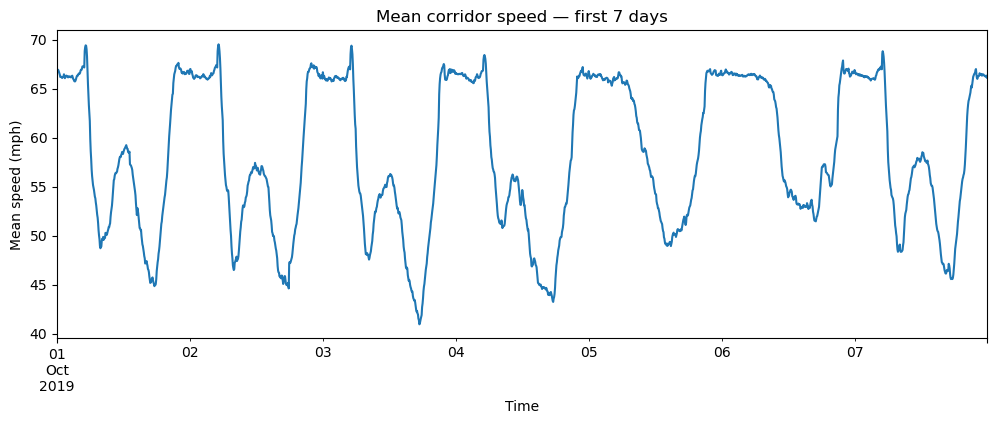

In [19]:
expected_per_day = 24 * 60 // SAMPLING_INTERVAL_MIN

corridor_speed = (
    df_corridor.groupby("Timestamp")["Avg Speed"]
    .mean()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(12, 4))
corridor_speed.iloc[: 7 * expected_per_day].plot(ax=ax)
ax.set_ylabel("Mean speed (mph)")
ax.set_xlabel("Time")
ax.set_title("Mean corridor speed — first 7 days")
plt.show()

### Average speed by hour of day

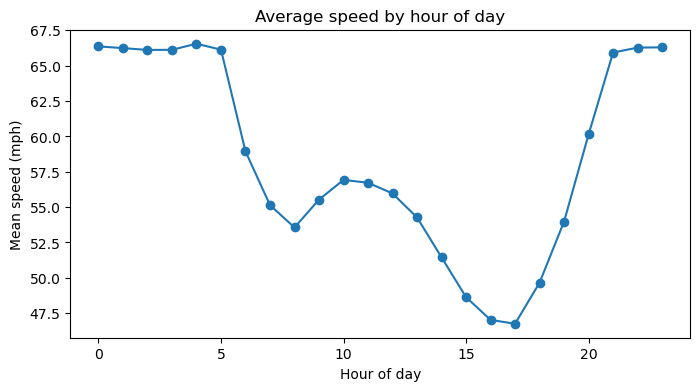

In [20]:
tmp = df_corridor[["Timestamp", "Avg Speed"]].copy()
tmp["hour"] = tmp["Timestamp"].dt.hour

hourly_profile = tmp.groupby("hour")["Avg Speed"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
hourly_profile.plot(ax=ax, marker="o")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean speed (mph)")
ax.set_title("Average speed by hour of day")
plt.show()

### Weekday versus weekend

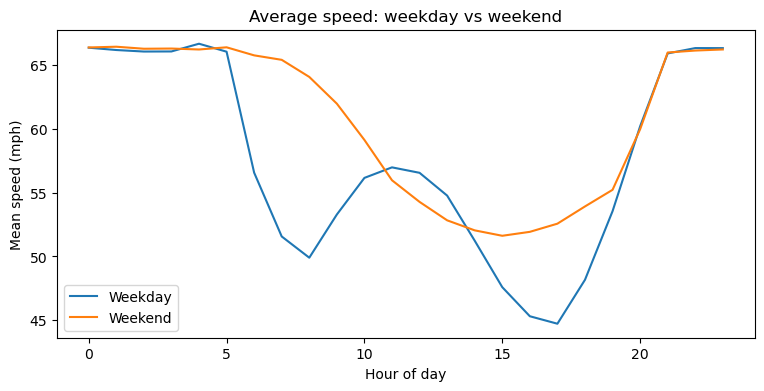

In [21]:
tmp = df_corridor[["Timestamp", "Avg Speed"]].copy()
tmp["is_weekend"] = tmp["Timestamp"].dt.dayofweek >= 5
tmp["hour"] = tmp["Timestamp"].dt.hour

profile = (
    tmp.groupby(["is_weekend", "hour"])["Avg Speed"]
    .mean()
    .unstack(0)
)

fig, ax = plt.subplots(figsize=(9, 4))
profile.plot(ax=ax)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean speed (mph)")
ax.set_title("Average speed: weekday vs weekend")
ax.legend(["Weekday", "Weekend"])
plt.show()

## 8. Compare travel directions

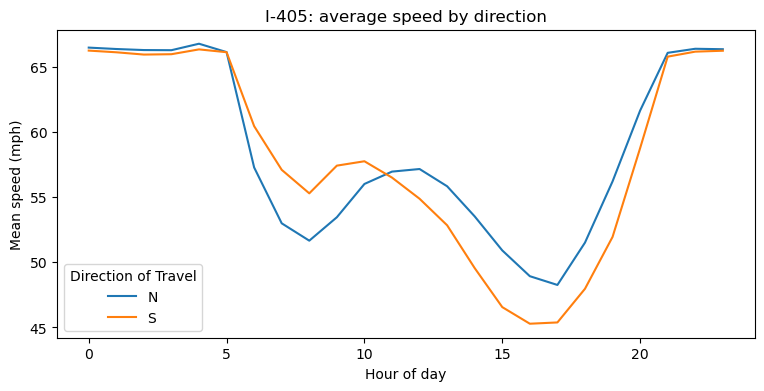

In [22]:
direction_profile = (
    df_corridor.assign(hour=df_corridor["Timestamp"].dt.hour)
    .groupby(["Direction of Travel", "hour"])["Avg Speed"]
    .mean()
    .unstack(0)
)

fig, ax = plt.subplots(figsize=(9, 4))
direction_profile.plot(ax=ax)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean speed (mph)")
ax.set_title(f"I-{FREEWAY}: average speed by direction")
plt.show()

## 9. Representative station

In [23]:
coverage = (
    df_corridor.groupby("Station")["Avg Speed"]
    .apply(lambda s: s.notna().mean())
    .sort_values(ascending=False)
)

representative_station = coverage.index[0]

station_df = (
    df_corridor.loc[df_corridor["Station"] == representative_station]
    .sort_values("Timestamp")
    .copy()
)

print("Representative station:", representative_station)
print("Speed coverage:", f"{coverage.iloc[0]:.2%}")
print("Direction:", station_df["Direction of Travel"].iloc[0])

display(station_df.head())

Representative station: 776741
Speed coverage: 100.00%
Direction: N


,Timestamp,Station,District,Freeway #,Direction of Travel,Lane Type,Station Length,Samples,% Observed,Total Flow,Avg Occupancy,Avg Speed
642,2019-10-01 00:00:00,776741,7,405,N,HV,0.28,0,0,57.0,0.0347,69.2
1285,2019-10-01 00:05:00,776741,7,405,N,HV,0.28,0,0,54.0,0.0346,69.1
1928,2019-10-01 00:10:00,776741,7,405,N,HV,0.28,0,0,55.0,0.0343,68.9
2571,2019-10-01 00:15:00,776741,7,405,N,HV,0.28,0,0,53.0,0.0332,68.6
3214,2019-10-01 00:20:00,776741,7,405,N,HV,0.28,0,0,50.0,0.0312,68.2


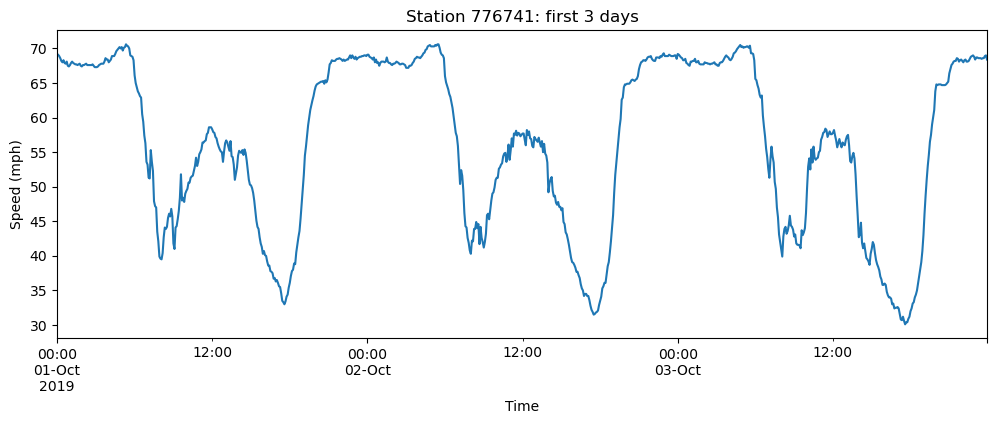

In [24]:
fig, ax = plt.subplots(figsize=(12, 4))

plot_data = station_df.set_index("Timestamp")["Avg Speed"].iloc[: 3 * expected_per_day]
plot_data.plot(ax=ax)

ax.set_xlabel("Time")
ax.set_ylabel("Speed (mph)")
ax.set_title(f"Station {representative_station}: first 3 days")
plt.show()

## 10. Thirty-minute persistence / transition analysis

This is still EDA rather than model training.

In [25]:
forecast_df = (
    df_corridor[["Station", "Timestamp", "Direction of Travel", "Avg Speed"]]
    .sort_values(["Station", "Timestamp"])
    .copy()
)

forecast_df["speed_30min_future"] = (
    forecast_df.groupby("Station")["Avg Speed"]
    .shift(-FORECAST_STEPS)
)

forecast_df["delta_speed_30min"] = (
    forecast_df["speed_30min_future"] - forecast_df["Avg Speed"]
)

forecast_valid = forecast_df.dropna(
    subset=["Avg Speed", "speed_30min_future"]
).copy()

print("Usable current/future pairs:", len(forecast_valid))
display(forecast_valid[["Avg Speed", "speed_30min_future", "delta_speed_30min"]].describe())

Usable current/future pairs: 3702215


,Avg Speed,speed_30min_future,delta_speed_30min
count,3.702215e+06,3.702215e+06,3.702215e+06
mean,5.835833e+01,5.835797e+01,-3.584071e-04
std,1.406366e+01,1.406374e+01,6.370655e+00
min,3.000000e+00,3.000000e+00,-6.800000e+01
25%,5.760000e+01,5.760000e+01,-1.200000e+00
50%,6.410000e+01,6.410000e+01,0.000000e+00
75%,6.550000e+01,6.550000e+01,1.200000e+00
max,8.490000e+01,8.490000e+01,6.960000e+01


### Current speed versus speed 30 minutes later

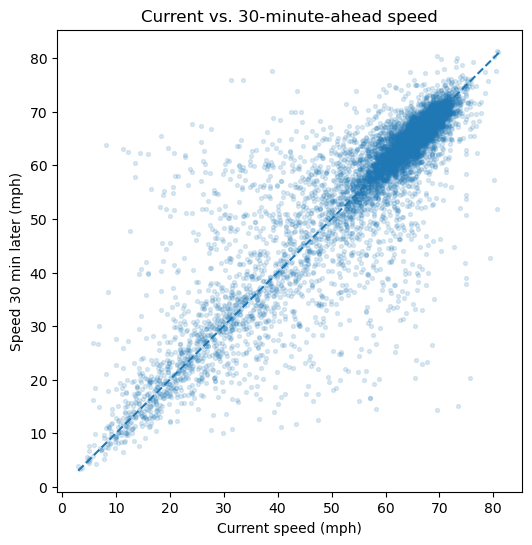

In [26]:
plot_sample = forecast_valid.sample(
    n=min(10000, len(forecast_valid)),
    random_state=42,
)

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    plot_sample["Avg Speed"],
    plot_sample["speed_30min_future"],
    alpha=0.15,
    s=8,
)

lims = [
    min(plot_sample["Avg Speed"].min(), plot_sample["speed_30min_future"].min()),
    max(plot_sample["Avg Speed"].max(), plot_sample["speed_30min_future"].max()),
]
ax.plot(lims, lims, linestyle="--")

ax.set_xlabel("Current speed (mph)")
ax.set_ylabel("Speed 30 min later (mph)")
ax.set_title("Current vs. 30-minute-ahead speed")
plt.show()

### Speed change over the next 30 minutes

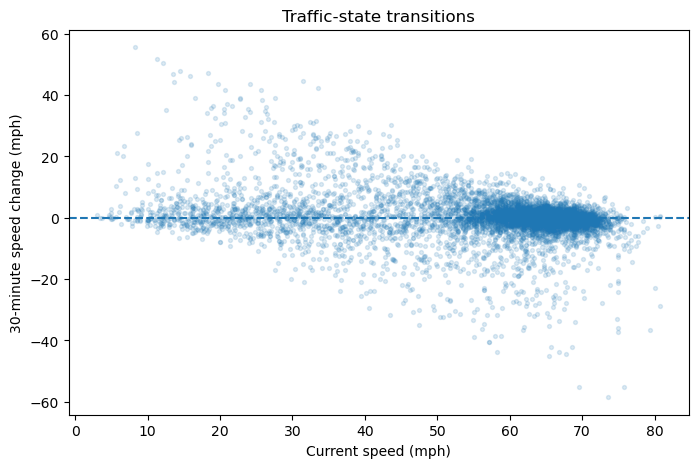

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    plot_sample["Avg Speed"],
    plot_sample["delta_speed_30min"],
    alpha=0.15,
    s=8,
)

ax.axhline(0, linestyle="--")
ax.set_xlabel("Current speed (mph)")
ax.set_ylabel("30-minute speed change (mph)")
ax.set_title("Traffic-state transitions")
plt.show()

## 11. Persistence baseline as an EDA sanity check

This is not a trained model. It measures the error from assuming future speed equals current speed.

In [28]:
errors = forecast_valid["speed_30min_future"] - forecast_valid["Avg Speed"]

persistence_mae = errors.abs().mean()
persistence_rmse = np.sqrt((errors ** 2).mean())

print(f"Persistence MAE:  {persistence_mae:.3f} mph")
print(f"Persistence RMSE: {persistence_rmse:.3f} mph")

Persistence MAE:  3.130 mph
Persistence RMSE: 6.371 mph


## 12. Candidate congestion thresholds

Do not finalize a threshold yet. First inspect the observed speed distribution.

In [29]:
speed_values = pd.to_numeric(df_corridor["Avg Speed"], errors="coerce").dropna()

quantiles = speed_values.quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)
display(quantiles.to_frame("Avg Speed (mph)"))

,Avg Speed (mph)
0.01,11.4
0.05,23.5
0.10,34.5
0.25,57.6
0.50,64.1
0.75,65.5
0.90,68.9
0.95,70.5
0.99,73.5


## 13. Candidate modeling subset

Use the EDA to decide:
- which direction to model,
- whether to keep all stations or a contiguous/high-coverage subset,
- minimum `% Observed`,
- missing-data handling,
- whether the primary target remains continuous speed or becomes congestion onset.

In [30]:
candidate_summary = (
    station_summary
    .sort_values(
        ["Direction of Travel", "speed_missing", "mean_observed"],
        ascending=[True, True, False]
    )
)

display(candidate_summary.head(30))

,Station,Direction of Travel,n_rows,start,end,speed_missing,flow_missing,occupancy_missing,mean_observed
357,762571,N,8927,2019-10-01,2019-10-31 23:55:00,0.0,0.0,0.0,99.988798
203,717818,N,8927,2019-10-01,2019-10-31 23:55:00,0.0,0.0,0.0,99.372690
204,717819,N,8927,2019-10-01,2019-10-31 23:55:00,0.0,0.0,0.0,99.372690
354,762565,N,8927,2019-10-01,2019-10-31 23:55:00,0.0,0.0,0.0,99.372690
355,762567,N,8927,2019-10-01,2019-10-31 23:55:00,0.0,0.0,0.0,99.372690
358,762573,N,8927,2019-10-01,2019-10-31 23:55:00,0.0,0.0,0.0,99.372690
466,767367,N,8927,2019-10-01,2019-10-31 23:55:00,0.0,0.0,0.0,99.372690
468,767369,N,8927,2019-10-01,2019-10-31 23:55:00,0.0,0.0,0.0,99.372690
469,767812,N,8927,2019-10-01,2019-10-31 23:55:00,0.0,0.0,0.0,99.372690
558,772024,N,8927,2019-10-01,2019-10-31 23:55:00,0.0,0.0,0.0,99.365296


## 14. Checkpoint summary

Fill this section in after running the notebook.

### Dataset
- Month:
- Freeway:
- District:
- Directions:
- Number of stations:
- Number of 5-minute records:
- Date range:

### Data quality
- Overall missingness:
- Typical `% Observed`:
- Stations with poor coverage:
- Duplicate/cadence issues:

### Traffic patterns
- Rush-hour pattern:
- Weekday/weekend differences:
- Directional differences:
- Evidence for distinct free-flow/congested regimes:

### Forecastability
- Current vs. 30-minute-ahead relationship:
- Persistence MAE:
- Persistence RMSE:
- Evidence for free-flow → congestion transitions:
- Evidence for congestion → recovery transitions:

### Decision for modeling
- Selected direction:
- Selected stations/corridor:
- Initial target:
- Initial feature set:
- Train/validation/test strategy:
- Provisional evaluation metrics: